<h1 align = "center">P2_Filtering_Sorting</h1>

### Import libraries

In [40]:
import pandas as pd

### Import dataset

In [43]:
path = "chipotle.tsv"

chipo = pd.read_csv(path, sep="\t")

In [45]:
chipo

,order_id,quantity,item_name,choice_description,item_price
0,1,1,Chips and Fresh Tomato Salsa,NaN,$2.39
1,1,1,Izze,[Clementine],$3.39
2,1,1,Nantucket Nectar,[Apple],$3.39
3,1,1,Chips and Tomatillo-Green Chili Salsa,NaN,$2.39
4,2,2,Chicken Bowl,"[Tomatillo-Red Chili Salsa (Hot), [Black Beans...",$16.98
...,...,...,...,...,...
4617,1833,1,Steak Burrito,"[Fresh Tomato Salsa, [Rice, Black Beans, Sour ...",$11.75
4618,1833,1,Steak Burrito,"[Fresh Tomato Salsa, [Rice, Sour Cream, Cheese...",$11.75
4619,1834,1,Chicken Salad Bowl,"[Fresh Tomato Salsa, [Fajita Vegetables, Pinto...",$11.25
4620,1834,1,Chicken Salad Bowl,"[Fresh Tomato Salsa, [Fajita Vegetables, Lettu...",$8.75


In [47]:
### Load our first rows

In [49]:
#Function

chipo.head()

,order_id,quantity,item_name,choice_description,item_price
0,1,1,Chips and Fresh Tomato Salsa,NaN,$2.39
1,1,1,Izze,[Clementine],$3.39
2,1,1,Nantucket Nectar,[Apple],$3.39
3,1,1,Chips and Tomatillo-Green Chili Salsa,NaN,$2.39
4,2,2,Chicken Bowl,"[Tomatillo-Red Chili Salsa (Hot), [Black Beans...",$16.98


In [51]:
### How many rows and columns we have?

In [53]:
chipo.shape

(4622, 5)

In [55]:
chipo.columns

Index(['order_id', 'quantity', 'item_name', 'choice_description',
       'item_price'],
      dtype='object')

In [57]:
chipo.index

RangeIndex(start=0, stop=4622, step=1)

In [59]:
### Which columns are categorical and which are numerical

In [61]:
categorical_cols = chipo.select_dtypes(include="object").columns
numerical_cols = chipo.select_dtypes(exclude="object").columns

print(categorical_cols)
print(numerical_cols)

Index(['item_name', 'choice_description', 'item_price'], dtype='object')
Index(['order_id', 'quantity'], dtype='object')


In [63]:
chipo.dtypes

order_id               int64
quantity               int64
item_name             object
choice_description    object
item_price            object
dtype: object

In [65]:
### Why item_price is not numerical??

In [67]:
chipo["item_price"].head(10)

0     $2.39 
1     $3.39 
2     $3.39 
3     $2.39 
4    $16.98 
5    $10.98 
6     $1.69 
7    $11.75 
8     $9.25 
9     $9.25 
Name: item_price, dtype: object

In [69]:
### Convert from $ to nothing

In [71]:
chipo["item_price"] = chipo.item_price.str.replace("$", "").astype(float)

In [73]:
chipo["item_price"].dtype

dtype('float64')

In [75]:
### Basic stat of our dataset

In [77]:
chipo.describe()

,order_id,quantity,item_price
count,4622.000000,4622.000000,4622.000000
mean,927.254868,1.075725,7.464336
std,528.890796,0.410186,4.245557
min,1.000000,1.000000,1.090000
25%,477.250000,1.000000,3.390000
50%,926.000000,1.000000,8.750000
75%,1393.000000,1.000000,9.250000
max,1834.000000,15.000000,44.250000


## Sorting and Filtering

In [80]:
### How many products costs more than $10??

In [82]:
# Non-missing
chipo[chipo.item_price > 10.00]["order_id"].count()

1130

In [84]:
# All
chipo[chipo.item_price > 10.00]["order_id"].size

1130

In [86]:
### Whats the price for each product??

In [88]:
prices = chipo[["item_name", "item_price"]]

prices

,item_name,item_price
0,Chips and Fresh Tomato Salsa,2.39
1,Izze,3.39
2,Nantucket Nectar,3.39
3,Chips and Tomatillo-Green Chili Salsa,2.39
4,Chicken Bowl,16.98
...,...,...
4617,Steak Burrito,11.75
4618,Steak Burrito,11.75
4619,Chicken Salad Bowl,11.25
4620,Chicken Salad Bowl,8.75


In [90]:
### Sort by the name 

In [92]:
chipo.item_name.sort_values()

3389    6 Pack Soft Drink
341     6 Pack Soft Drink
1849    6 Pack Soft Drink
1860    6 Pack Soft Drink
2713    6 Pack Soft Drink
              ...        
2384    Veggie Soft Tacos
781     Veggie Soft Tacos
2851    Veggie Soft Tacos
1699    Veggie Soft Tacos
1395    Veggie Soft Tacos
Name: item_name, Length: 4622, dtype: object

In [94]:
chipo.sort_values(by="item_name")

,order_id,quantity,item_name,choice_description,item_price
3389,1360,2,6 Pack Soft Drink,[Diet Coke],12.98
341,148,1,6 Pack Soft Drink,[Diet Coke],6.49
1849,749,1,6 Pack Soft Drink,[Coke],6.49
1860,754,1,6 Pack Soft Drink,[Diet Coke],6.49
2713,1076,1,6 Pack Soft Drink,[Coke],6.49
...,...,...,...,...,...
2384,948,1,Veggie Soft Tacos,"[Roasted Chili Corn Salsa, [Fajita Vegetables,...",8.75
781,322,1,Veggie Soft Tacos,"[Fresh Tomato Salsa, [Black Beans, Cheese, Sou...",8.75
2851,1132,1,Veggie Soft Tacos,"[Roasted Chili Corn Salsa (Medium), [Black Bea...",8.49
1699,688,1,Veggie Soft Tacos,"[Fresh Tomato Salsa, [Fajita Vegetables, Rice,...",11.25


In [96]:
### Whats the quantity of the most expensive item ordered?

In [98]:
chipo.sort_values(by="item_price", ascending = False)["quantity"].head(1)

3598    15
Name: quantity, dtype: int64

In [100]:
s = chipo.sort_values(by="item_price", ascending=False)["quantity"]

a = s.head(1).values[0]
b = s.iloc[0]
c = s.head(1).item()

print(a, "->", type(a).__name__)
print(b, "->", type(b).__name__)
print(c, "->", type(c).__name__)

15 -> int64
15 -> int64
15 -> int


In [102]:
### How many times the Veggie Salad Bowl was ordered?

In [104]:
chipo[chipo.item_name == "Veggie Salad Bowl"]["quantity"].sum()

18

In [106]:
### How many times did someone order more than 1 Canned Soda?

In [108]:
condition = (chipo.item_name == "Canned Soda") & (chipo.quantity > 1)

chipo[condition]["quantity"].count()

20

In [110]:
### How many different products were sold? 

In [112]:
unique_values = chipo["item_name"].nunique()

unique_values

50

In [114]:
### Whats the total revenue

In [116]:
total_revenue = (chipo["item_price"] * chipo["quantity"]).sum()

print(round(total_revenue))

39237


In [118]:
### Whats the average price of items

In [120]:
average_price = chipo["item_price"].mean()

print(round(average_price, 10))

7.4643357854


In [122]:
### How many orders were made in total?

In [124]:
chipo["order_id"].nunique()

1834

In [126]:
### What is the total quantity of items ordered?

In [128]:
chipo["quantity"].sum()

4972

In [130]:
### Which item has the highest average price?

In [132]:
# Groupby

chipo.groupby("item_name")["item_price"].mean().idxmax()


'Bowl'

In [134]:
### Which item is the most-ordered item?

In [136]:
chipo.groupby("item_name")["quantity"].sum().idxmax()

'Chicken Bowl'

In [138]:
#Option 2
c = chipo.groupby("item_name")
c = c.sum()
c = c.sort_values(["quantity"], ascending = False)

c.reset_index().item_name.head(1)

0    Chicken Bowl
Name: item_name, dtype: object

In [140]:
### Group our dataset by item_name and count how many times each product appears

In [142]:
chipo.groupby("item_name").size().sort_values()

item_name
Carnitas Salad                             1
Veggie Crispy Tacos                        1
Chips and Mild Fresh Tomato Salsa          1
Crispy Tacos                               2
Bowl                                       2
Salad                                      2
Steak Salad                                4
Veggie Salad                               6
Carnitas Salad Bowl                        6
Burrito                                    6
Carnitas Crispy Tacos                      7
Veggie Soft Tacos                          7
Chicken Salad                              9
Barbacoa Salad Bowl                       10
Barbacoa Crispy Tacos                     11
Veggie Salad Bowl                         18
Chips and Roasted Chili-Corn Salsa        18
Izze                                      20
Chips and Tomatillo-Red Chili Salsa       20
Chips and Roasted Chili Corn Salsa        22
Barbacoa Soft Tacos                       25
Nantucket Nectar                          27


In [144]:
### Calculate the total quantity sold for each product

In [146]:
item_quantity = chipo.groupby("item_name")["quantity"].sum()

item_quantity

item_name
6 Pack Soft Drink                         55
Barbacoa Bowl                             66
Barbacoa Burrito                          91
Barbacoa Crispy Tacos                     12
Barbacoa Salad Bowl                       10
Barbacoa Soft Tacos                       25
Bottled Water                            211
Bowl                                       4
Burrito                                    6
Canned Soda                              126
Canned Soft Drink                        351
Carnitas Bowl                             71
Carnitas Burrito                          60
Carnitas Crispy Tacos                      8
Carnitas Salad                             1
Carnitas Salad Bowl                        6
Carnitas Soft Tacos                       40
Chicken Bowl                             761
Chicken Burrito                          591
Chicken Crispy Tacos                      50
Chicken Salad                              9
Chicken Salad Bowl                       123


In [148]:
### Whats the average quantity per order?

In [150]:
avg_items_per_order = chipo.groupby("order_id")["quantity"].mean()

avg_items_per_order

order_id
1       1.0
2       2.0
3       1.0
4       1.0
5       1.0
       ... 
1830    1.0
1831    1.0
1832    1.0
1833    1.0
1834    1.0
Name: quantity, Length: 1834, dtype: float64

In [152]:
### Visualization

In [154]:
###Plot the top 5 most ordered items

<Axes: ylabel='Frequency'>

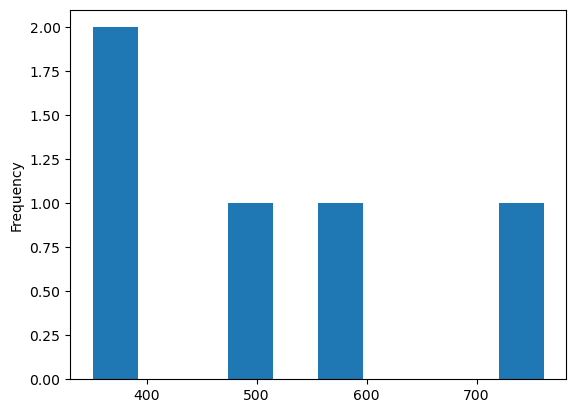

In [156]:
top5 = chipo.groupby("item_name")["quantity"].sum().sort_values(ascending=False).head(5)

top5.plot(kind="hist")

In [158]:
### Plot the total quantity sold for the top 10

<Axes: xlabel='item_name'>

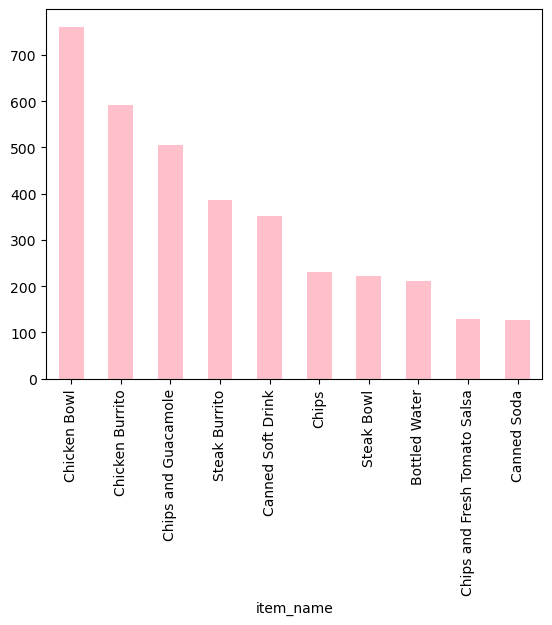

In [168]:
top5 = chipo.groupby("item_name")["quantity"].sum().sort_values(ascending=False).head(10)

top5.plot(kind="bar", color = "pink")

In [162]:
### Calculate the total revenue generated by each product and plot the top 12 highest-revenue 

In [164]:
chipo['revenue'] = chipo["quantity"] * chipo["item_price"]

<Axes: xlabel='item_name'>

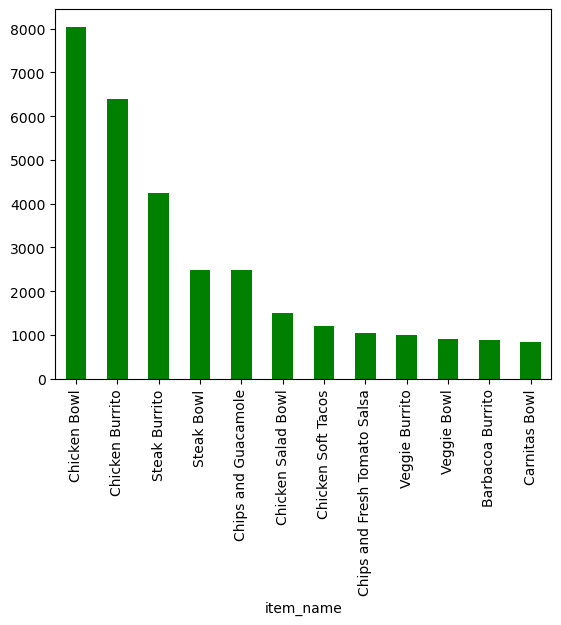

In [166]:
chipo.groupby("item_name")["revenue"].sum().sort_values(ascending = False).head(12).plot(kind="bar", color="green")

<Axes: xlabel='item_name'>

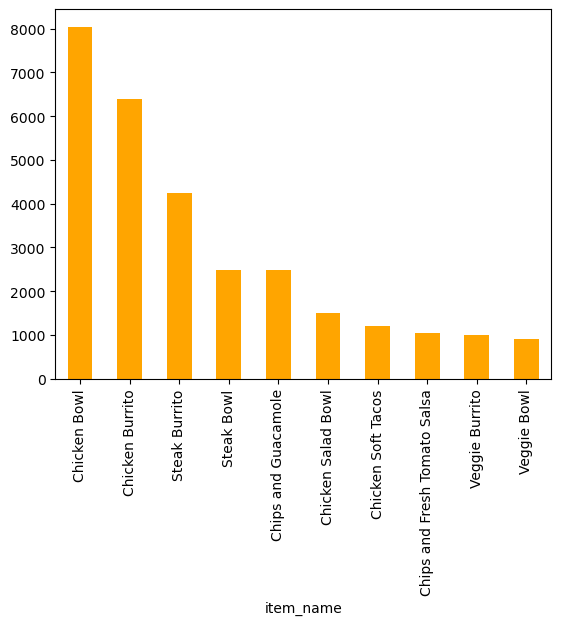

In [313]:
# option 2
revenue = (chipo["item_price"] * chipo["quantity"]).groupby(chipo["item_name"]).sum()

top10_revenue = revenue.sort_values(ascending=False).head(10)

top10_revenue.plot(kind="bar", color="orange")

In [315]:
chipo

,order_id,quantity,item_name,choice_description,item_price,revenue
0,1,1,Chips and Fresh Tomato Salsa,NaN,2.39,2.39
1,1,1,Izze,[Clementine],3.39,3.39
2,1,1,Nantucket Nectar,[Apple],3.39,3.39
3,1,1,Chips and Tomatillo-Green Chili Salsa,NaN,2.39,2.39
4,2,2,Chicken Bowl,"[Tomatillo-Red Chili Salsa (Hot), [Black Beans...",16.98,33.96
...,...,...,...,...,...,...
4617,1833,1,Steak Burrito,"[Fresh Tomato Salsa, [Rice, Black Beans, Sour ...",11.75,11.75
4618,1833,1,Steak Burrito,"[Fresh Tomato Salsa, [Rice, Sour Cream, Cheese...",11.75,11.75
4619,1834,1,Chicken Salad Bowl,"[Fresh Tomato Salsa, [Fajita Vegetables, Pinto...",11.25,11.25
4620,1834,1,Chicken Salad Bowl,"[Fresh Tomato Salsa, [Fajita Vegetables, Lettu...",8.75,8.75


In [317]:
chipo["choice_description"].value_counts().head(1)

choice_description
[Diet Coke]    134
Name: count, dtype: int64

In [353]:
order_grouped = chipo.groupby("order_id")["item_price"].mean()

order_grouped

order_id
1        2.890000
2       16.980000
3        6.335000
4       10.500000
5        6.850000
          ...    
1830    11.500000
1831     4.300000
1832     6.600000
1833    11.750000
1834     9.583333
Name: item_price, Length: 1834, dtype: float64

In [321]:
chipo.groupby("item_name")["quantity"].sum().sort_values(ascending=False).head(1)

item_name
Chicken Bowl    761
Name: quantity, dtype: int64

In [323]:
chipo.groupby("item_name")["item_price"].mean()

item_name
6 Pack Soft Drink                         6.610185
Barbacoa Bowl                            10.187273
Barbacoa Burrito                          9.832418
Barbacoa Crispy Tacos                    10.928182
Barbacoa Salad Bowl                      10.640000
Barbacoa Soft Tacos                      10.018400
Bottled Water                             1.867654
Bowl                                     14.800000
Burrito                                   7.400000
Canned Soda                               1.320577
Canned Soft Drink                         1.457641
Carnitas Bowl                            10.833971
Carnitas Burrito                         10.132712
Carnitas Crispy Tacos                    11.137143
Carnitas Salad                            8.990000
Carnitas Salad Bowl                      11.056667
Carnitas Soft Tacos                       9.398500
Chicken Bowl                             10.113953
Chicken Burrito                          10.082857
Chicken Crispy Tacos 

In [325]:
chipo["choice_description"].value_counts().idxmax()

'[Diet Coke]'